Install packages

In [14]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import requests
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import xgboost as xgb
import json

Get the data

In [15]:
data = pd.read_csv('../datasets/AAPL.csv')
data.head(100)

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,1980-12-12 00:00:00-05:00,0.098834,0.099264,0.098834,0.098834,469033600,0.0,0.0
1,1980-12-15 00:00:00-05:00,0.094108,0.094108,0.093678,0.093678,175884800,0.0,0.0
2,1980-12-16 00:00:00-05:00,0.087232,0.087232,0.086802,0.086802,105728000,0.0,0.0
3,1980-12-17 00:00:00-05:00,0.088951,0.089381,0.088951,0.088951,86441600,0.0,0.0
4,1980-12-18 00:00:00-05:00,0.091530,0.091959,0.091530,0.091530,73449600,0.0,0.0
...,...,...,...,...,...,...,...,...
95,1981-04-30 00:00:00-04:00,0.097545,0.098405,0.097545,0.097545,12611200,0.0,0.0
96,1981-05-01 00:00:00-04:00,0.097545,0.098405,0.097545,0.097545,16553600,0.0,0.0
97,1981-05-04 00:00:00-04:00,0.097545,0.097545,0.097116,0.097116,14448000,0.0,0.0
98,1981-05-05 00:00:00-04:00,0.097116,0.097116,0.096686,0.096686,17539200,0.0,0.0


Remove every entry before 2004

In [16]:
data = data[data['Date'] >= '2004-01-01']

#Convert every date to datetime
data['Date'] = pd.to_datetime(data['Date'], utc=True)

Calculating Features about data 

In [17]:
data['Quarter'] = data['Date'].dt.quarter
data['week_number'] = data['Date'].dt.isocalendar().week
data['week_day'] = data['Date'].dt.weekday
data['month']  = data['Date'].dt.month


Add inflation values 

(the inflation api only has values for the first day of each year, so it is being applied the same value for each day of that year)

In [18]:
# Load inflation data from a JSON file
with open('../datasets/economic_indicators/inflation.json', 'r') as file:  # Update the path to your JSON file
    data_inflation = json.load(file)

# Print the structure of the loaded data for debugging
print(data_inflation)  # Check the structure of the JSON data

# Assuming data_inflation is a list, adjust the mapping accordingly
inflation_mapping = {}
for item in data_inflation:  # Iterate over the list
    if 'date' in item and 'value' in item:  # Ensure the keys exist
        inflation_mapping[item['date'][:4]] = float(item['value'])

# Add inflation value for 2024
inflation_mapping['2024'] = 2.6

# Add a new column for Inflation to the dataset
data['Inflation'] = None

# Apply the inflation value for each row based on the year
for index, row in data.iterrows():
    year = row['Date'].year
    if str(year) in inflation_mapping:
        data.at[index, 'Inflation'] = inflation_mapping[str(year)]

# Ensure 'Inflation' column is numeric
data['Inflation'] = pd.to_numeric(data['Inflation'], errors='coerce')

# Check for NaNs in the column after conversion
if data['Inflation'].isnull().any():
    print("Found NaNs in 'Inflation' column after conversion. Filling with a default value (e.g., median).")
    data['Inflation'].fillna(data['Inflation'].median(), inplace=True)


[{'date': '2023-01-01', 'value': 4.11633838374488}, {'date': '2022-01-01', 'value': 8.00279982052121}, {'date': '2021-01-01', 'value': 4.69785886363742}, {'date': '2020-01-01', 'value': 1.23358439630629}, {'date': '2019-01-01', 'value': 1.81221007526021}, {'date': '2018-01-01', 'value': 2.44258329692817}, {'date': '2017-01-01', 'value': 2.13011000365961}, {'date': '2016-01-01', 'value': 1.26158320570536}, {'date': '2015-01-01', 'value': 0.118627135552451}, {'date': '2014-01-01', 'value': 1.62222297740817}, {'date': '2013-01-01', 'value': 1.46483265562717}, {'date': '2012-01-01', 'value': 2.06933726526067}, {'date': '2011-01-01', 'value': 3.156841568622}, {'date': '2010-01-01', 'value': 1.6400434423899}, {'date': '2009-01-01', 'value': -0.355546266299747}, {'date': '2008-01-01', 'value': 3.839100296651}, {'date': '2007-01-01', 'value': 2.85267248150138}, {'date': '2006-01-01', 'value': 3.22594410070404}, {'date': '2005-01-01', 'value': 3.3927468454955}, {'date': '2004-01-01', 'value': 2

Addition of CPI (Consumer Price Index) data 

- The CPI is retrieved monthly

In [19]:
with open('../datasets/economic_indicators/cpi.json', 'r') as file:
    cpi_data = json.load(file)

cpi_mapping = {}
for entry in cpi_data:
    if 'date' in entry and 'value' in entry:  
        cpi_mapping[entry['date'][:7]] = float(entry['value']) 

data['YearMonth'] = data['Date'].dt.strftime('%Y-%m')  


data['CPI'] = data['YearMonth'].map(cpi_mapping) 

data.drop(columns=['YearMonth'], inplace=True)

if data['CPI'].isnull().any():
    data['CPI'].fillna(data['CPI'].median(), inplace=True) 

C:\Users\Miguel Rodrigues\AppData\Local\Temp\ipykernel_6420\2835526113.py:17: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['CPI'].fillna(data['CPI'].median(), inplace=True)


Add interest rate feature

In [20]:
with open('../datasets/economic_indicators/interest_rates.json', 'r') as file:
    interest_data = json.load(file)

interest_mapping = {}
for entry in interest_data:
    if 'date' in entry and 'value' in entry: 
        year_month = entry['date'][:7]
        interest_mapping[year_month] = float(entry['value'])

data['YearMonth'] = data['Date'].dt.strftime('%Y-%m')

data['Interest Rate'] = data['YearMonth'].map(interest_mapping) 

data.drop(columns=['YearMonth'], inplace=True)
if data['Interest Rate'].isnull().any():
    data['Interest Rate'].fillna(data['Interest Rate'].median(), inplace=True)

Add GDP feature

In [21]:
# with open('../datasets/economic_indicators/real_gdp.json', 'r') as file:
#     gdp_data = json.load(file)

# real_gdp_quarterly = gdp_data.get('data', [])

# real_gdp_mapping = {
#     entry['date'][:4] + '-Q' + str((int(entry['date'][5:7]) - 1) // 3 + 1): entry['value']
#     for entry in real_gdp_quarterly
# }

# def get_quarterly_gdp_from_quarter(row):
#     quarter_key = row['Date'].strftime('%Y') + '-Q' + str(row['Quarter'])
#     return real_gdp_mapping.get(quarter_key, None)

# data['REAL_GDP'] = data.apply(get_quarterly_gdp_from_quarter, axis=1)

Create / calculating new features 

In [22]:
#### Price Based Features #####

# Daily Range
data["Daily Range"] = data["High"] - data["Low"]

# 3. Direction
data["Direction"] = (data["Close"] > data["Open"]).astype(int)

# 4. Percentage Change
data["Percentage Change"] = ((data["Close"] - data["Open"]) / data["Open"]) * 100

# 6. Momentum (10-day)
data["Momentum_10"] = data["Close"] - data["Close"].shift(10)

# ===================== VOLUME-BASED FEATURES =====================
# Volume Change (Percentage)
data['Volume Change'] = data['Volume'].pct_change() * 100

# ===================== RETURN-BASED FEATURES =====================

# Daily Return
data['Daily Return'] = data['Close'].pct_change()
data['Next Day Return'] = data['Daily Return'].shift(-1) * 100
data['Next Week Return'] = data['Daily Return'].shift(-7)
data['Next Month Return'] = data['Daily Return'].shift(-30)
# data['Next Year Return'] = data['Daily Return'].shift(-365)

# 2. Calculate returns over different periods
data['7-Day Return'] = (data['Close'] / data['Close'].shift(7) - 1) * 100  # 7 days
data['1-Month Return'] = (data['Close'] / data['Close'].shift(30) - 1) * 100  # 30 days
data['6-Month Return'] = (data['Close'] / data['Close'].shift(182) - 1) * 100  # ~6 months
data['1-Year Return'] = (data['Close'] / data['Close'].shift(365) - 1) * 100  # 1 year

data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5262 entries, 5820 to 11081
Data columns (total 28 columns):
 #   Column             Non-Null Count  Dtype              
---  ------             --------------  -----              
 0   Date               5262 non-null   datetime64[ns, UTC]
 1   Open               5262 non-null   float64            
 2   High               5262 non-null   float64            
 3   Low                5262 non-null   float64            
 4   Close              5262 non-null   float64            
 5   Volume             5262 non-null   int64              
 6   Dividends          5262 non-null   float64            
 7   Stock Splits       5262 non-null   float64            
 8   Quarter            5262 non-null   int32              
 9   week_number        5262 non-null   UInt32             
 10  week_day           5262 non-null   int32              
 11  month              5262 non-null   int32              
 12  Inflation          5262 non-null   float64       

Correlation Matrix

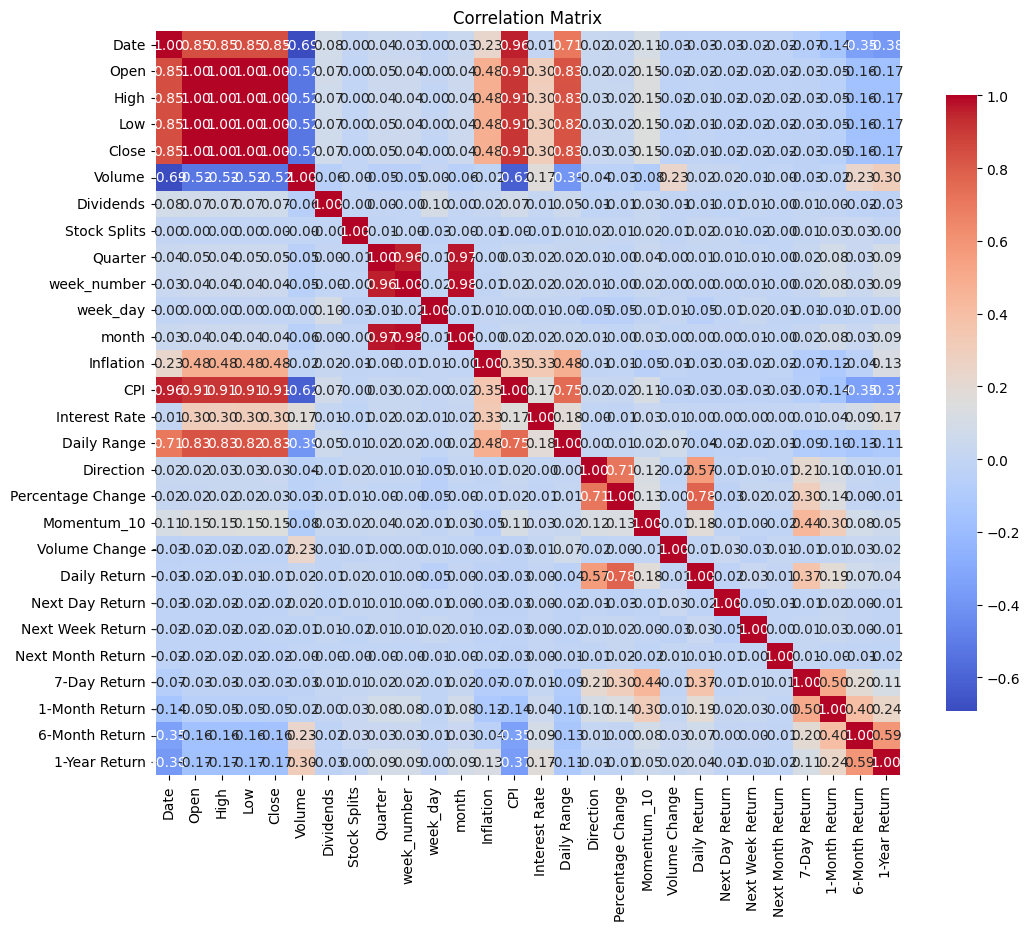

In [23]:
correlation_matrix = data.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True, cbar_kws={"shrink": .8})
plt.title('Correlation Matrix')
plt.show()

Distribution plots

In [24]:
# Calculate Z-scores
data['Z-Score'] = (data['Daily Return'] - data['Daily Return'].mean()) / data['Daily Return'].std()

# Remove outliers
data_no_outliers = data[(data['Z-Score'] >= -2.5) & (data['Z-Score'] <= 2.5)]

data = data_no_outliers
data.shape

(5121, 29)

Box plots

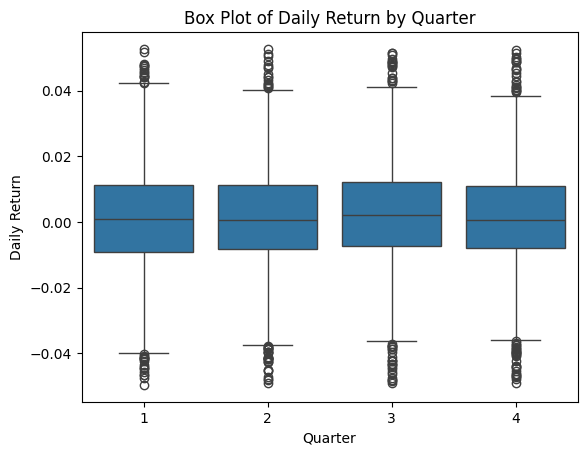

In [25]:
# Box plot for Daily Return by Quarter
sns.boxplot(x='Quarter', y='Daily Return', data=data)
plt.title('Box Plot of Daily Return by Quarter')
plt.xlabel('Quarter')
plt.ylabel('Daily Return')
plt.show()

(XG BOOST) Train the model and make predictions

Mean Squared Error: 4.0389
R-Squared: -0.3964


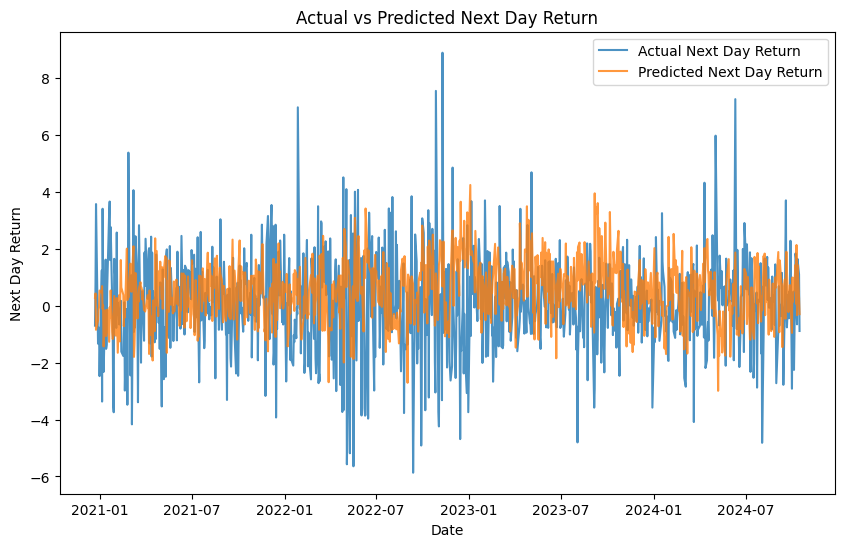

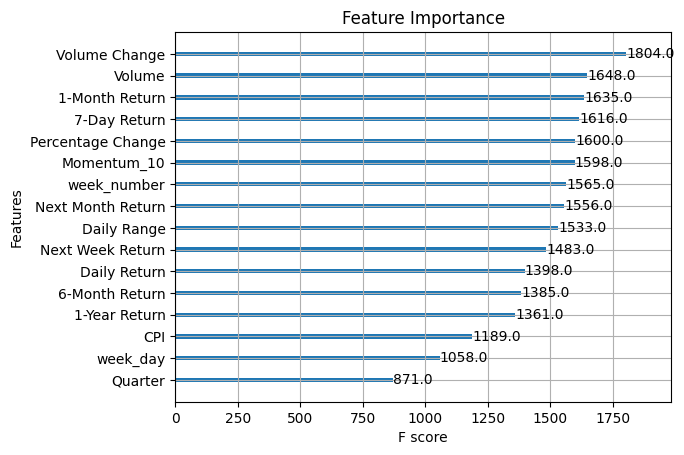

In [26]:
data = data.dropna()
target = 'Next Day Return'
features = [
    'Quarter', 'week_number', 'week_day', 'CPI',
    'Daily Range', 'Volume', 'Momentum_10', 'Volume Change',
    'Percentage Change', '7-Day Return', '1-Month Return', '6-Month Return',
    '1-Year Return', 'Daily Return', 'Next Week Return', 'Next Month Return'
]


inputData = data[features]
targetVariable = data[target]

input_train, input_test, target_train, target_test = train_test_split(inputData, targetVariable,test_size=0.2, random_state=42, shuffle=False)

model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    objective='reg:squarederror',
    random_state=42,
    booster="dart"
)

# Train the model
model.fit(input_train, target_train)

# Predict on the test set
target_pred = model.predict(input_test)

# mean_squared_error = The lower the better, indicates a better fit of the model to the data, meaning the predictions are closer to the actual values.
mse = mean_squared_error(target_test, target_pred) 
# r2_score = Closer to 1 is better , capacity of the model to explain variability
r2 = r2_score(target_test, target_pred) 
print(f"Mean Squared Error: {mse:.4f}")
print(f"R-Squared: {r2:.4f}")

# Plot predictions vs actuals
plt.figure(figsize=(10, 6))
plt.plot(data['Date'][-len(target_test):], target_test, label=f'Actual {target}', alpha=0.8)
plt.plot(data['Date'][-len(target_test):], target_pred, label=f'Predicted {target}', alpha=0.8)
plt.legend()
plt.title(f'Actual vs Predicted {target}')
plt.xlabel('Date')
plt.ylabel(target)
plt.show()

xgb.plot_importance(model)
plt.title('Feature Importance')
plt.show()


RANDOM FOREST

Mean Squared Error: 3.2880
R-Squared: -0.1368


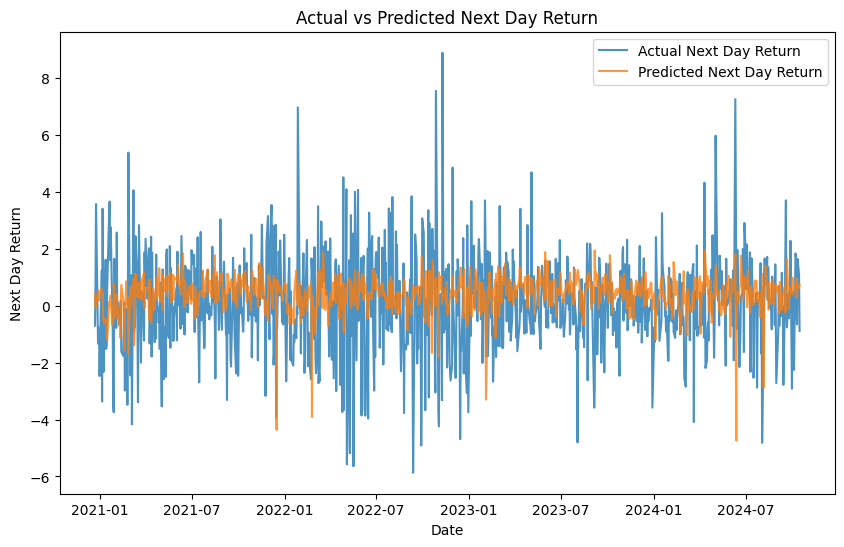

In [27]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# Assuming 'data' is your DataFrame and 'target' is your target variable
data = data.dropna()  # Ensure there are no missing values
target = 'Next Day Return'  # Example target variable
features = [
    'Quarter', 'week_number', 'week_day', 'CPI',
    'Daily Range', 'Volume', 'Momentum_10', 'Volume Change',
    'Percentage Change', '7-Day Return', '1-Month Return', '6-Month Return',
    '1-Year Return', 'Daily Return', 'Next Week Return', 'Next Month Return'
]

# Prepare the input data
inputData = data[features]
targetVariable = data[target]

# Split the data into training and testing sets
input_train, input_test, target_train, target_test = train_test_split(inputData, targetVariable, test_size=0.2, random_state=42, shuffle=False)

# Define the Random Forest model
model = RandomForestRegressor(
    n_estimators=500,  # Number of trees in the forest
    random_state=42,
    max_depth=None,  # You can set a maximum depth if needed
    min_samples_split=2,  # Minimum number of samples required to split an internal node
    min_samples_leaf=1,  # Minimum number of samples required to be at a leaf node
)

# Train the model
model.fit(input_train, target_train)

# Predict on the test set
target_pred = model.predict(input_test)

# Calculate Mean Squared Error and R-Squared
mse = mean_squared_error(target_test, target_pred)
r2 = r2_score(target_test, target_pred)

print(f"Mean Squared Error: {mse:.4f}")
print(f"R-Squared: {r2:.4f}")

# Plot predictions vs actuals
plt.figure(figsize=(10, 6))
plt.plot(data['Date'][-len(target_test):], target_test, label=f'Actual {target}', alpha=0.8)
plt.plot(data['Date'][-len(target_test):], target_pred, label=f'Predicted {target}', alpha=0.8)
plt.legend()
plt.title('Actual vs Predicted Next Day Return')
plt.xlabel('Date')
plt.ylabel('Next Day Return')
plt.show()

LIGHT GBM

Mean Squared Error: 4.2020
R-Squared: -0.4528


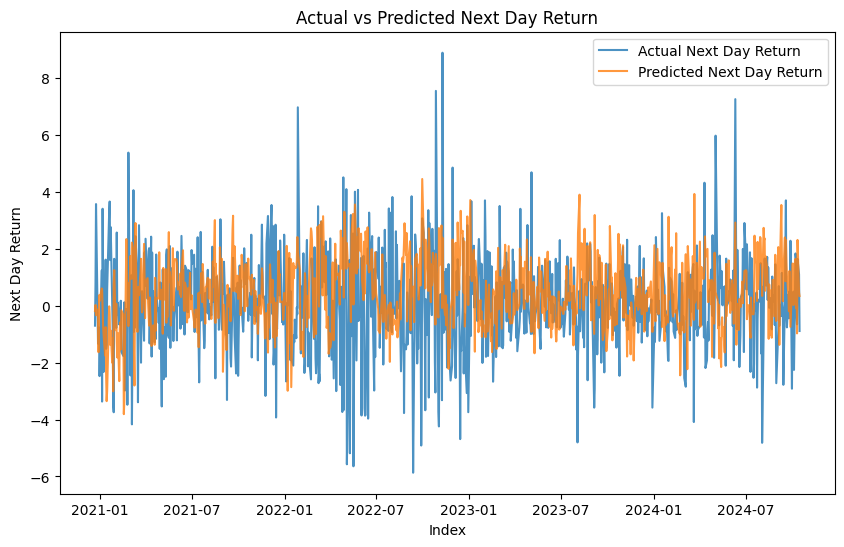

In [28]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import lightgbm as lgb
import matplotlib.pyplot as plt

# Assuming 'data' is your DataFrame and 'target' is your target variable
data = data.dropna()  # Ensure there are no missing values
target = 'Next Day Return'  # Example target variable
features = [
    'Quarter', 'week_number', 'week_day', 'CPI',
    'Daily Range', 'Volume', 'Momentum_10', 'Volume Change',
    'Percentage Change', '7-Day Return', '1-Month Return', '6-Month Return',
    '1-Year Return', 'Daily Return', 'Next Week Return', 'Next Month Return'
]

# Prepare the input data
inputData = data[features]
targetVariable = data[target]

# Split the data into training and testing sets
input_train, input_test, target_train, target_test = train_test_split(inputData, targetVariable, test_size=0.2, random_state=42, shuffle=False)

# Create LightGBM dataset
train_data = lgb.Dataset(input_train, label=target_train)
test_data = lgb.Dataset(input_test, label=target_test, reference=train_data)

# Set parameters for LightGBM
params = {
    'objective': 'regression',
    'metric': 'mse',
    'boosting_type': 'gbdt',  # Gradient Boosting Decision Tree
    'num_leaves': 31,          # Number of leaves in one tree
    'learning_rate': 0.05,
    'feature_fraction': 0.9,   # Fraction of features to use
    'bagging_fraction': 0.8,    # Fraction of data to use for bagging
    'bagging_freq': 5,          # Frequency of bagging
    'verbose': -1               # Verbosity of the output
}

# Train the model
model = lgb.train(params, train_data, valid_sets=[test_data], num_boost_round=1000)

# Predict on the test set
target_pred = model.predict(input_test, num_iteration=model.best_iteration)

# Calculate Mean Squared Error and R-Squared
mse = mean_squared_error(target_test, target_pred)
r2 = r2_score(target_test, target_pred)

print(f"Mean Squared Error: {mse:.4f}")
print(f"R-Squared: {r2:.4f}")

# Plot predictions vs actuals
plt.figure(figsize=(10, 6))
plt.plot(data['Date'][-len(target_test):], target_test, label=f'Actual {target}', alpha=0.8)
plt.plot(data['Date'][-len(target_test):], target_pred, label=f'Predicted {target}', alpha=0.8)
plt.legend()
plt.title('Actual vs Predicted Next Day Return')
plt.xlabel('Index')
plt.ylabel('Next Day Return')
plt.show()